In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/monkeypox-skin-lesion-dataset/Monkeypox_Dataset_metadata.csv
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M34_02_07.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M53_01_02.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M50_03_04.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M34_04_07.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M34_01_09.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M34_03_13.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M17_02_10.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M50_03_06.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M17_01_13.jpg
/kaggle/input/monkeypox-skin-lesion-dataset/Fold1/Fold1/Fold1/Val/Monkeypox/M34_02_10.jpg
/kaggle/input/monkeypox-s


Fold 1
Epoch 1/30: Train Loss: 0.2812, Train Acc: 0.8825, Val Loss: 0.1466, Val Acc: 0.9515
Epoch 2/30: Train Loss: 0.0891, Train Acc: 0.9734, Val Loss: 0.0905, Val Acc: 0.9687
Epoch 3/30: Train Loss: 0.0575, Train Acc: 0.9816, Val Loss: 0.0557, Val Acc: 0.9781
Epoch 4/30: Train Loss: 0.0276, Train Acc: 0.9910, Val Loss: 0.1347, Val Acc: 0.9531
Epoch 5/30: Train Loss: 0.0544, Train Acc: 0.9824, Val Loss: 0.0716, Val Acc: 0.9781
Epoch 6/30: Train Loss: 0.0310, Train Acc: 0.9914, Val Loss: 0.0316, Val Acc: 0.9890
Epoch 7/30: Train Loss: 0.0038, Train Acc: 0.9988, Val Loss: 0.0286, Val Acc: 0.9906
Epoch 8/30: Train Loss: 0.0004, Train Acc: 1.0000, Val Loss: 0.0295, Val Acc: 0.9906
Epoch 9/30: Train Loss: 0.0002, Train Acc: 1.0000, Val Loss: 0.0308, Val Acc: 0.9890
Epoch 10/30: Train Loss: 0.0002, Train Acc: 1.0000, Val Loss: 0.0319, Val Acc: 0.9890
Epoch 11/30: Train Loss: 0.0001, Train Acc: 1.0000, Val Loss: 0.0329, Val Acc: 0.9890
Epoch 12/30: Train Loss: 0.0001, Train Acc: 1.0000, Val

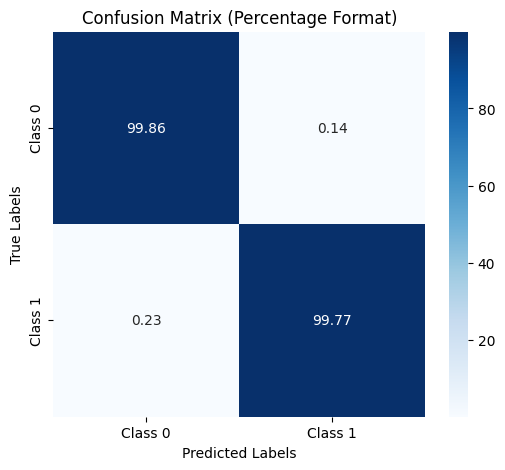

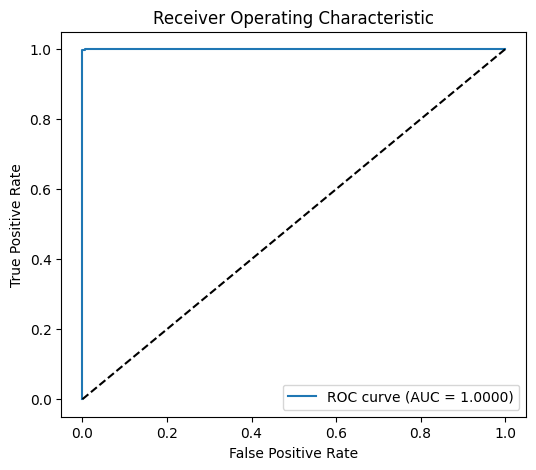

In [4]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from torchvision import transforms
from torch.utils.data import DataLoader, Subset, TensorDataset
from transformers import ViTModel
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------
# Parameters and Transformations
# ---------------------------
folder_path = "/kaggle/input/monkeypox-skin-lesion-dataset/Augmented Images/Augmented Images"
subfolders = ['Monkeypox_augmented', 'Others_augmented']
image_size = (224, 224)
batch_size = 16
epochs = 30
learning_rate = 0.0001

transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# ---------------------------
# Load Dataset
# ---------------------------
data = []
labels = []
label_map = {subfolder: idx for idx, subfolder in enumerate(subfolders)}

for subfolder in subfolders:
    subfolder_path = os.path.join(folder_path, subfolder)
    for filename in os.listdir(subfolder_path):
        img_path = os.path.join(subfolder_path, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, image_size)
            data.append(img)
            labels.append(label_map[subfolder])

data = np.array(data).astype("float32")
labels = np.array(labels)

# Convert data to tensors and arrange dimensions (N, C, H, W)
data = torch.tensor(data).permute(0, 3, 1, 2) / 255.0  # normalize to [0, 1]
labels = torch.tensor(labels)
dataset = TensorDataset(data, labels)

# ---------------------------
# Device Setup
# ---------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------
# Load Pre-trained ViT Model from Hugging Face Transformers
# ---------------------------
vit_model = ViTModel.from_pretrained("google/vit-base-patch16-224-in21k").to(device)

# ---------------------------
# Define Custom Classification Model with GELU Activation
# ---------------------------
class ViTClassifierWithGELU(nn.Module):
    def __init__(self, vit_model, num_classes):
        super(ViTClassifierWithGELU, self).__init__()
        self.vit_model = vit_model
        self.classifier = nn.Sequential(
            nn.Linear(self.vit_model.config.hidden_size, 512),
            nn.GELU(),  # Using GELU activation
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, pixel_values):
        outputs = self.vit_model(pixel_values=pixel_values).last_hidden_state
        cls_token = outputs[:, 0, :]  # Extract the CLS token
        return self.classifier(cls_token)

# ---------------------------
# Training Function
# ---------------------------
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs):
    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        train_preds = []
        train_targets = []
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(pixel_values=images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            total_train_loss += loss.item() * images.size(0)
            train_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            train_targets.extend(labels.cpu().numpy())
        avg_train_loss = total_train_loss / len(train_loader.dataset)
        train_accuracy = accuracy_score(train_targets, train_preds)
        
        model.eval()
        total_val_loss = 0.0
        val_preds = []
        val_targets = []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(pixel_values=images)
                loss = criterion(outputs, labels)
                total_val_loss += loss.item() * images.size(0)
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())
        avg_val_loss = total_val_loss / len(val_loader.dataset)
        val_accuracy = accuracy_score(val_targets, val_preds)
        
        print(f"Epoch {epoch+1}/{epochs}: Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.4f}, " \
              f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.4f}")

# ---------------------------
# Evaluation Function (for classification metrics)
# ---------------------------
def evaluate_model(model, test_loader):
    model.eval()
    test_preds = []
    test_targets = []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            test_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            test_targets.extend(labels.cpu().numpy())
    precision = precision_score(test_targets, test_preds, average='weighted')
    recall = recall_score(test_targets, test_preds, average='weighted')
    f1 = f1_score(test_targets, test_preds, average='weighted')
    accuracy = accuracy_score(test_targets, test_preds)
    return accuracy, precision, recall, f1

# ---------------------------
# Evaluation Function (to gather probabilities for ROC curve)
# ---------------------------
def evaluate_model_with_probs(model, loader):
    model.eval()
    all_targets = []
    all_probs = []  # save probability score for class 1 values
    all_preds = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            all_probs.extend(probs[:, 1].cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
    return all_targets, all_probs, all_preds

# ---------------------------
# Plotting Functions
# ---------------------------
def plot_confusion_matrix_func(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    cm_percentage = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True) * 100
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_percentage, annot=True, fmt=".2f", cmap="Blues", 
                xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title("Confusion Matrix (Percentage Format)")
    plt.show()

def plot_roc_curve_from_scores(y_true, y_score):
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    roc_auc = roc_auc_score(y_true, y_score)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic")
    plt.legend(loc="lower right")
    plt.show()

# ---------------------------
# K-Fold Cross-Validation Training
# ---------------------------
criterion = nn.CrossEntropyLoss()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []
global_targets = []
global_probs = []
global_preds = []

for fold, (train_indices, val_indices) in enumerate(kf.split(dataset)):
    print(f"\nFold {fold+1}")
    
    # Create data loaders for the current fold
    train_subset = Subset(dataset, train_indices)
    val_subset = Subset(dataset, val_indices)
    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
    
    # Reinitialize model and optimizer for this fold
    model = ViTClassifierWithGELU(vit_model, num_classes=2).to(device)
    optimizer = AdamW(model.parameters(), lr=learning_rate)
    
    # Train the model on current fold
    train_model(model, train_loader, val_loader, criterion, optimizer, epochs)
    
    # Evaluate on validation set with categorical metrics
    accuracy, precision, recall, f1_value = evaluate_model(model, val_loader)
    print(f"Fold {fold+1} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, " \
          f"Recall: {recall:.4f}, F1 Score: {f1_value:.4f}")
    fold_results.append((accuracy, precision, recall, f1_value))
    
    # Gather outputs from validation set for ROC and confusion matrix plotting
    targets, probs, preds = evaluate_model_with_probs(model, val_loader)
    global_targets.extend(targets)
    global_probs.extend(probs)
    global_preds.extend(preds)

# Calculate average metrics over folds
average_results = np.mean(fold_results, axis=0)
print("\n5-Fold Cross-Validation Results:")
print(f"Average Accuracy: {average_results[0]:.4f}")
print(f"Average Precision: {average_results[1]:.4f}")
print(f"Average Recall: {average_results[2]:.4f}")
print(f"Average F1 Score: {average_results[3]:.4f}")

# ---------------------------
# Additional Evaluation: Plot Confusion Matrix and ROC Curve
# ---------------------------
plot_confusion_matrix_func(global_targets, global_preds)
plot_roc_curve_from_scores(global_targets, global_probs)
